# Import

In [1]:
%reset -f
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import meshio
from time import time
import sys
sys.path.append('../')

from sources.parameters import *
from sources.data import *
from sources.model import *
from sources.solver import *

# make data

In [2]:
gen = data_generator(ub,lb)

In [3]:
X_r, X_data, u_data = gen.gen_train_data(1_000_000,5_000,5_000)

In [4]:
X_r

<tf.Tensor: shape=(1000000, 3), dtype=float32, numpy=
array([[0.70802486, 0.44458592, 0.8047862 ],
       [0.79343355, 0.778707  , 0.25982678],
       [0.46460927, 0.13507509, 0.5121982 ],
       ...,
       [0.7737671 , 0.59504104, 0.07701123],
       [0.7071841 , 0.5789368 , 0.6513754 ],
       [0.20752668, 0.5225301 , 0.11932743]], dtype=float32)>

In [5]:
X_data, u_data = gen.add_data([300, 350, 400])
X_data, u_data

(<tf.Tensor: shape=(9107, 3), dtype=float32, numpy=
 array([[ 0.       , -3.       ,  3.       ],
        [ 0.       , -2.8      ,  3.       ],
        [ 0.       , -2.87845  ,  2.869491 ],
        ...,
        [ 1.       ,  2.8520296, -2.8595142],
        [ 1.       ,  2.8      , -3.       ],
        [ 1.       ,  3.       , -3.       ]], dtype=float32)>,
 <tf.Tensor: shape=(9107, 4), dtype=float32, numpy=
 array([[-4.6371811e-39, -8.1760160e-41,  4.0224875e-39, -2.8333333e+00],
        [-6.8371832e-39, -9.1459318e-39,  5.4744849e-39, -2.8218527e+00],
        [-1.3542451e-08, -6.9479613e-09,  4.5848099e-09, -2.6957872e+00],
        ...,
        [ 6.6478920e-09, -3.1817288e-07,  7.1349575e-09,  2.6841998e+00],
        [ 7.1857801e-38, -2.2232497e-37,  5.4345818e-38,  2.8218527e+00],
        [ 4.5700084e-38,  6.1471460e-40,  4.4576638e-38,  2.8333333e+00]],
       dtype=float32)>)

### training

In [6]:
model = PhysicsInformedNN(lb, ub, output_dim=4, num_hidden_layers=8, num_neurons_per_layer=256, activation='tanh')
model.build(input_shape=(None,3))
#model.load_weights(WEIGHT_PATH+'best_weight_MHD.h5')

solver = VinciSolver(model, batch_size = 3_000)

t0 = time()
try: 
    lr = tf.keras.optimizers.schedules.ExponentialDecay(
        1e-3,
        decay_steps=100,
        decay_rate=0.97,
        staircase=True)
    optim = tf.keras.optimizers.Adam(learning_rate=lr)
    solver.solve_with_TFoptimizer(optim, X_r, X_data, u_data)
    alert(str(solver.best_loss))
    solver.solve_with_TFoptimizer(optim, X_r, X_data, u_data)
except:
  pass

print('\nTraining time: {} seconds'.format(time()-t0))
alert('MHD')

Epoch 19_900: 

                    phi_r1       5.0477e-04  
                    phi_r2       2.8748e-04
                    phi_r3       6.2689e-03
                    phi_r4       2.6542e-04
                    phi_0_omega  8.9717e-03
                    phi_0_phi    1.6453e-03
                    phi_0_J      7.0888e-04
                    phi_0_psi    6.8906e-04
                    total_loss   1.9342e-02

Training time: 9260.685693979263 seconds


<AxesSubplot:xlabel='Iteration', ylabel='Loss'>

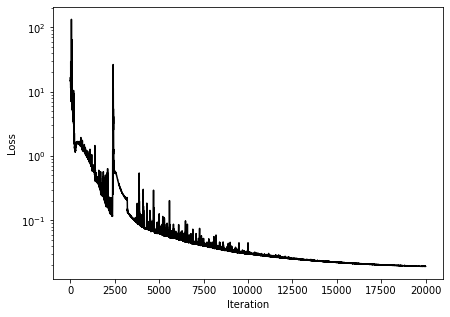

In [7]:
solver.plot_loss_history()

# Check results

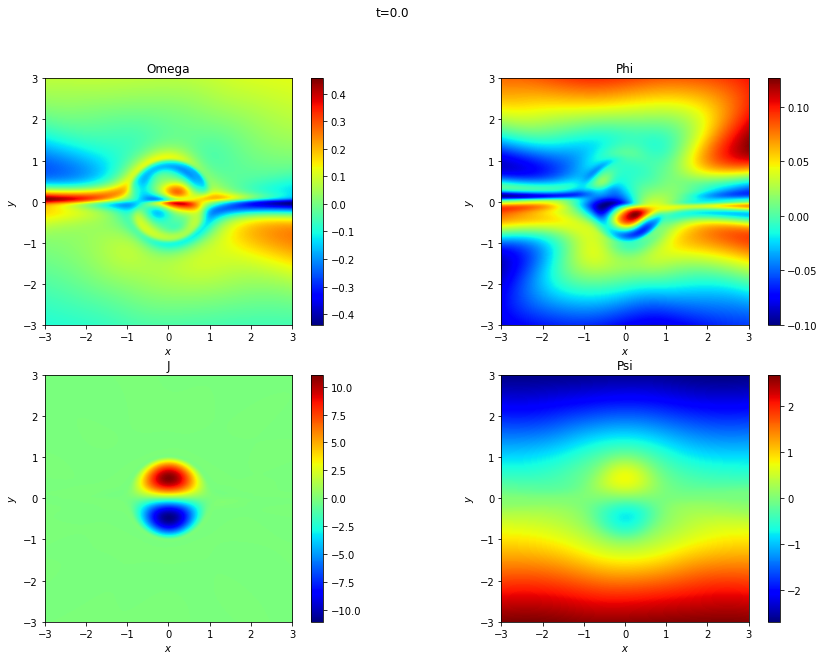

In [8]:
N = 500
t = 0.

# compute solution using PINN
xspace = np.linspace(-3,3,N)
yspace = np.linspace(-3,3,N)
tfinal = t * np.ones(N*N)

X, Y = np.meshgrid(xspace, yspace)
Xgrid = np.vstack([tfinal.flatten(), X.flatten(), Y.flatten()]).T
u = model(tf.cast(Xgrid,DTYPE))

omega, phi, J, psi = u[:,0:1], u[:,1:2], u[:,2:3], u[:,3:4]

# reshape for plotting
omega = omega.numpy().reshape(N,N)
phi = phi.numpy().reshape(N,N)
J = J.numpy().reshape(N,N)
psi = psi.numpy().reshape(N,N)

# affichage
fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(15,10))
axs = axs.flatten()

# plot omega
axs[0].set_xlabel('$x$')
axs[0].set_ylabel('$y$')
axs[0].set_aspect('equal')
img0 = axs[0].imshow(omega, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar0 = plt.colorbar(img0, ax=axs[0])
axs[0].set_title('Omega')

# plot phi
axs[1].set_xlabel('$x$')
axs[1].set_ylabel('$y$')
axs[1].set_aspect('equal')
img1 = axs[1].imshow(phi, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar1 = plt.colorbar(img1, ax=axs[1])
axs[1].set_title('Phi')

# plot J
axs[2].set_xlabel('$x$')
axs[2].set_ylabel('$y$')
axs[2].set_aspect('equal')
img2 = axs[2].imshow(J, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar2 = plt.colorbar(img2, ax=axs[2])
axs[2].set_title('J')

# plot psi
axs[3].set_xlabel('$x$')
axs[3].set_ylabel('$y$')
axs[3].set_aspect('equal')
img3 = axs[3].imshow(psi, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar3 = plt.colorbar(img3, ax=axs[3])
axs[3].set_title('Psi')

#fig.tight_layout()
plt.suptitle('t={}'.format(t))
plt.show()

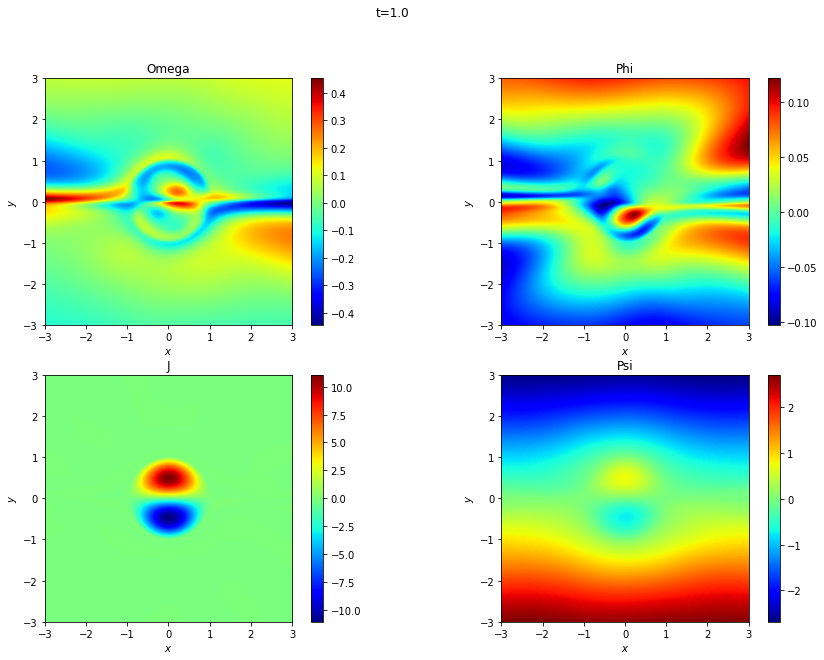

In [9]:
N = 500
t = 1.

# compute solution using PINN
xspace = np.linspace(-3,3,N)
yspace = np.linspace(-3,3,N)
tfinal = t * np.ones(N*N)

X, Y = np.meshgrid(xspace, yspace)
Xgrid = np.vstack([tfinal.flatten(), X.flatten(), Y.flatten()]).T
u = model(tf.cast(Xgrid,DTYPE))

omega, phi, J, psi = u[:,0:1], u[:,1:2], u[:,2:3], u[:,3:4]

# reshape for plotting
omega = omega.numpy().reshape(N,N)
phi = phi.numpy().reshape(N,N)
J = J.numpy().reshape(N,N)
psi = psi.numpy().reshape(N,N)

# affichage
fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(15,10))
axs = axs.flatten()

# plot omega
axs[0].set_xlabel('$x$')
axs[0].set_ylabel('$y$')
axs[0].set_aspect('equal')
img0 = axs[0].imshow(omega, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar0 = plt.colorbar(img0, ax=axs[0])
axs[0].set_title('Omega')

# plot phi
axs[1].set_xlabel('$x$')
axs[1].set_ylabel('$y$')
axs[1].set_aspect('equal')
img1 = axs[1].imshow(phi, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar1 = plt.colorbar(img1, ax=axs[1])
axs[1].set_title('Phi')

# plot J
axs[2].set_xlabel('$x$')
axs[2].set_ylabel('$y$')
axs[2].set_aspect('equal')
img2 = axs[2].imshow(J, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar2 = plt.colorbar(img2, ax=axs[2])
axs[2].set_title('J')

# plot psi
axs[3].set_xlabel('$x$')
axs[3].set_ylabel('$y$')
axs[3].set_aspect('equal')
img3 = axs[3].imshow(psi, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar3 = plt.colorbar(img3, ax=axs[3])
axs[3].set_title('Psi')

#fig.tight_layout()
plt.suptitle('t={}'.format(t))
plt.show()